# Compara surrogates y transfiere a minerales no vistos

**Pregunta:** ¿Cuánto cambia el desempeño predictivo cuando se excluye del entrenamiento un grupo mineral completo?

Nivel: 3. Requisitos previos: Niveles 1 y 2 de este tema. Tiempo de lectura: 28 minutos.

## Objetivos

Compara familias de modelos con objetivos y filas de prueba idénticos, inspecciona transferencia de caso completo y cobertura GP, y evalúa los límites de generalización que permite la evidencia.

## Preparación

```bash
pip install numpy==2.2.6 scipy==1.17.1 pandas==2.2.3 matplotlib==3.11.2 nbclient==0.11.0 nbformat==5.11.1 ipykernel==7.4.0 SALib==1.6.0
```

El pipeline OreFlow se importa desde `data-pipeline/`; este notebook nunca instala paquetes.

Para la lección de nivel 3 sobre 03-learning, registra las versiones fijadas antes de ejecutar el análisis; así se puede reconstruir el entorno que produjo cada tabla y figura.

In [1]:
# Importa herramientas de análisis y registra sus versiones exactas.
import importlib.metadata
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resuelve el pipeline local desde la estructura relativa del repositorio.
repo = Path("../../../").resolve()
sys.path.insert(0, str(repo / "data-pipeline"))
for package in ("numpy", "scipy", "pandas", "matplotlib", "nbclient", "nbformat", "ipykernel"):
    print(package, importlib.metadata.version(package))


numpy 2.2.6
scipy 1.17.1
pandas 2.2.3
matplotlib 3.11.2
nbclient 0.11.0
nbformat 5.11.1
ipykernel 7.4.0


## Datos

Responsable: autores de OreFlow; `data/derived/learning.json` contiene resultados versionados de 3.072 estados simulados en doce circuitos de autoría propia, licencia MIT del proyecto. Las etiquetas las genera el motor, no son datos observados de planta. Repositorio: https://github.com/fsantibanezleal/CAOS_OreFlow.

## Método

El portafolio de producción incluye Ridge, random forest, histogram gradient boosting, proceso gaussiano y MLP PyTorch. Registra RMSE, MAE y $R^2$ en interpolación, caso no visto y grupo de mineral no visto. La cobertura empírica revisa intervalos GP nominales del 95%. La importancia por permutación indica dependencia en el dominio de prueba, no causalidad.

## Comparación

Random forests (Breiman, 2001), gradient boosting (Friedman, 2001), procesos gaussianos (Rasmussen y Williams, 2006) y redes entrenadas con Adam (Kingma y Ba, 2015) son métodos establecidos. OreFlow los compara en un diseño común generado por el motor y audita transferencia, métricas por caso, cobertura e identificación fuera de envolvente. No se afirma un algoritmo nuevo ni una mejora validada en planta; doce circuitos propios acotan lo que este registro respalda.

Lee la evaluación comprometida y sus casos, identidades de modelos y tamaños de partición declarados.

In [2]:
# Lee la evaluación comprometida y sus casos, identidades de modelos y tamaños de partición
# declarados.
record = json.loads((repo / "data/derived/learning.json").read_text(encoding="utf-8"))
print("versión del motor:", record["engine_version"])
print("design:", record["design"])
print("models:", record["models"])
print(
    "interpolation rows:",
    record["interpolation"]["train_rows"],
    "train /",
    record["interpolation"]["test_rows"],
    "test",
)
print(
    "folds por caso:",
    len(record["leave_one_case_out"]),
    "| group folds:",
    len(record["leave_one_group_out"]),
)


versión del motor: 0.10.007
design: {'per_case': 256, 'cases': ['copper_porphyry_soft', 'copper_porphyry_hard', 'gold_free_milling', 'iron_magnetite_fine', 'nickel_sulphide', 'phosphate_clay', 'copper_molybdenum', 'copper_oxide', 'zinc_sulfide', 'mixed_ore_high_clay', 'low_grade_copper', 'refractory_gold'], 'rows': 3072, 'seed': 20260927, 'seconds': 555.6779085000016, 'method': "scrambled Sobol over each case's Contract 1 envelope and ore factors"}
models: ['ridge', 'random_forest', 'hist_gradient_boosting', 'gaussian_process', 'mlp']
interpolation rows: 2460 train / 612 test
folds por caso: 12 | group folds: 2


Compara errores de recuperación en las mismas filas de interpolación. R² agrupado y dentro de caso responden preguntas distintas.

In [3]:
# Compara errores de recuperación en las mismas filas de interpolación.
target = "recovery_pct"
rows = []
for name, values in record["interpolation"]["models"].items():
    metric = values[target]
    rows.append(
        {
            "model": name,
            "RMSE (%)": metric["rmse"],
            "MAE (%)": metric["mae"],
            "pooled R²": metric["r2"],
            "within-case R²": metric["r2_within_case"],
        }
    )
score = pd.DataFrame(rows).set_index("model").sort_values("RMSE (%)")
display(score.round(3))


,RMSE (%),MAE (%),pooled R²,within-case R²
model,,,,
mlp,3.382,1.675,0.951,0.936
hist_gradient_boosting,4.603,3.178,0.909,0.881
gaussian_process,5.344,3.600,0.878,0.840
random_forest,6.492,4.538,0.820,0.764
ridge,9.460,6.825,0.617,0.498


Grafica RMSE por objetivo, conservando sus unidades. Compara modelos dentro de cada columna; no ordenes recuperación, log-upgrade y energía en una escala común.

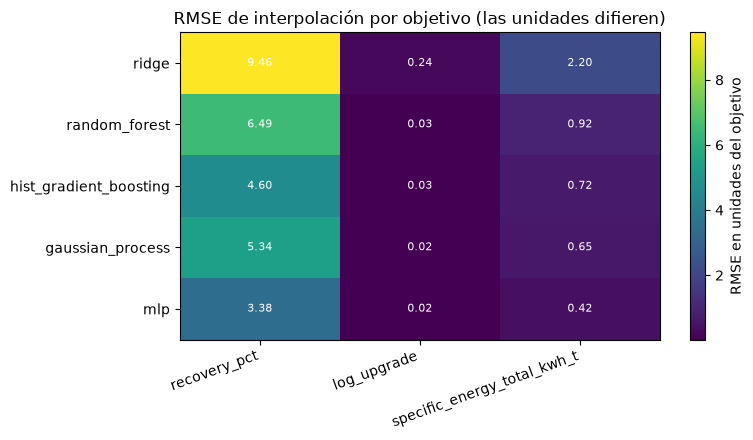

In [4]:
# Grafica RMSE por objetivo, conservando sus unidades.
model_names, targets = record["models"], record["targets"]
rmse = np.array(
    [[record["interpolation"]["models"][m][t]["rmse"] for t in targets] for m in model_names]
)
fig, ax = plt.subplots(figsize=(8, 4.5))
im = ax.imshow(rmse, aspect="auto", cmap="viridis")
ax.set_xticks(range(len(targets)), targets, rotation=20, ha="right")
ax.set_yticks(range(len(model_names)), model_names)
ax.set_title("RMSE de interpolación por objetivo (las unidades difieren)")
for i in range(len(model_names)):
    for j in range(len(targets)):
        ax.text(j, i, f"{rmse[i, j]:.2f}", ha="center", va="center", color="white", fontsize=8)
fig.colorbar(im, ax=ax, label="RMSE en unidades del objetivo")
fig.tight_layout()


La figura 14 de nivel 3 sobre 03 learning informa salidas de puntos operativos resueltos por separado. En la figura 14 de nivel 3 sobre 03 learning, cada marca es una evaluación separada del modelo en el ajuste indicado. En la figura 14 de nivel 3 sobre 03 learning, contrasta recuperación, tamaño y energía con el contrato. La línea de la figura 14 solo guía la comparación.

Inspecciona transferencia a casos no vistos y cobertura de intervalos. Un buen resultado de interpolación no promete desempeño en un grupo de mineral ausente del entrenamiento.

In [5]:
# Inspecciona transferencia a casos no vistos y cobertura de intervalos.
case_scores = [
    {
        "held-out case": f["held_out"],
        "RMSE (%)": f["models"]["random_forest"]["recovery_pct"]["rmse"],
    }
    for f in record["leave_one_case_out"]
]
group_scores = [
    {
        "held-out ore group": f["held_out_group"],
        "RMSE (%)": f["models"]["random_forest"]["recovery_pct"]["rmse"],
    }
    for f in record["leave_one_group_out"]
]
print("Worst leave-one-case-out recovery scores:")
display(pd.DataFrame(case_scores).sort_values("RMSE (%)", ascending=False).head(5))
print("Leave-one-ore-group-out recovery scores:")
display(pd.DataFrame(group_scores).sort_values("RMSE (%)", ascending=False))
gp = record["interpolation"]["models"]["gaussian_process"]
print("cobertura nominal 95% del intervalo GP:", {t: gp[t]["coverage_95"] for t in targets})


Worst leave-one-case-out recovery scores:


,held-out case,RMSE (%)
3,iron_magnetite_fine,48.862763
11,refractory_gold,15.406035
7,copper_oxide,14.117908
2,gold_free_milling,12.480387
8,zinc_sulfide,11.880682


Leave-one-ore-group-out recovery scores:


,held-out ore group,RMSE (%)
0,Cu:chalcopyrite,13.925760
1,Au:pyrite,10.712957


cobertura nominal 95% del intervalo GP: {'recovery_pct': 0.9068627450980392, 'log_upgrade': 0.9133986928104575, 'specific_energy_total_kwh_t': 0.9379084967320261}


En el caso de nivel 3 sobre 03 learning, la corrida con 0.8× el tratamiento nominal cambia la alimentación fresca y mantiene los demás controles en su punto nominal de autoría. En el caso de nivel 3 sobre 03 learning, con 0.8× de alimentación, recuperación, tamaño y energía son salidas acopladas del circuito resuelto.

In [6]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_porphyry_soft")
factor = 0.8
point_0_8 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_0_8 = simulate(case.ore, case.plant, point_0_8)
print("throughput (t/h):", round(point_0_8.throughput_tph, 2))
print("recovery (%):", round(response_0_8.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_0_8.metrics["p80_um"], 2))


throughput (t/h): 576.0
recovery (%): 93.788
product P80 (µm): 150.0


En el caso de nivel 3 sobre 03 learning, la corrida con 0.9× el tratamiento nominal cambia la alimentación fresca y mantiene los demás controles en su punto nominal de autoría. En el caso de nivel 3 sobre 03 learning, con 0.9× de alimentación, recuperación, tamaño y energía son salidas acopladas del circuito resuelto.

In [7]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_porphyry_soft")
factor = 0.9
point_0_9 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_0_9 = simulate(case.ore, case.plant, point_0_9)
print("throughput (t/h):", round(point_0_9.throughput_tph, 2))
print("recovery (%):", round(response_0_9.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_0_9.metrics["p80_um"], 2))


throughput (t/h): 648.0
recovery (%): 92.996
product P80 (µm): 150.0


En el caso de nivel 3 sobre 03 learning, la corrida con 1.0× el tratamiento nominal cambia la alimentación fresca y mantiene los demás controles en su punto nominal de autoría. En el caso de nivel 3 sobre 03 learning, con 1.0× de alimentación, recuperación, tamaño y energía son salidas acopladas del circuito resuelto.

In [8]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_porphyry_soft")
factor = 1.0
point_1_0 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_1_0 = simulate(case.ore, case.plant, point_1_0)
print("throughput (t/h):", round(point_1_0.throughput_tph, 2))
print("recovery (%):", round(response_1_0.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_1_0.metrics["p80_um"], 2))


throughput (t/h): 720.0
recovery (%): 92.213
product P80 (µm): 150.0


En el caso de nivel 3 sobre 03 learning, la corrida con 1.1× el tratamiento nominal cambia la alimentación fresca y mantiene los demás controles en su punto nominal de autoría. En el caso de nivel 3 sobre 03 learning, con 1.1× de alimentación, recuperación, tamaño y energía son salidas acopladas del circuito resuelto.

In [9]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_porphyry_soft")
factor = 1.1
point_1_1 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_1_1 = simulate(case.ore, case.plant, point_1_1)
print("throughput (t/h):", round(point_1_1.throughput_tph, 2))
print("recovery (%):", round(response_1_1.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_1_1.metrics["p80_um"], 2))


throughput (t/h): 792.0
recovery (%): 91.437
product P80 (µm): 150.0


En el caso de nivel 3 sobre 03 learning, la corrida con 1.2× el tratamiento nominal cambia la alimentación fresca y mantiene los demás controles en su punto nominal de autoría. En el caso de nivel 3 sobre 03 learning, con 1.2× de alimentación, recuperación, tamaño y energía son salidas acopladas del circuito resuelto.

In [10]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_porphyry_soft")
factor = 1.2
point_1_2 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_1_2 = simulate(case.ore, case.plant, point_1_2)
print("throughput (t/h):", round(point_1_2.throughput_tph, 2))
print("recovery (%):", round(response_1_2.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_1_2.metrics["p80_um"], 2))


throughput (t/h): 864.0
recovery (%): 88.442
product P80 (µm): 165.93


En la lección de nivel 3 sobre 03 learning, la lectura del gráfico 1 considera en esta figura del nivel 3 sobre 03 learning, compara la recuperación con el P80 de producto al variar el tratamiento. En la lección de nivel 3 sobre 03 learning, la lectura del gráfico 2 considera los ejes separan unidades distintas, así que el cambio describe el caso de autoría propia y no una tendencia empírica de planta. En la lección de nivel 3 sobre 03 learning, la lectura del gráfico 3 considera el punto nominal sirve como referencia para los ajustes vecinos. En la lección de nivel 3 sobre 03 learning, la lectura del gráfico 4 considera en «Compara surrogates y transfiere a minerales no vistos», cada punto procede de una evaluación independiente del motor y las líneas solo guían la vista entre ajustes probados.

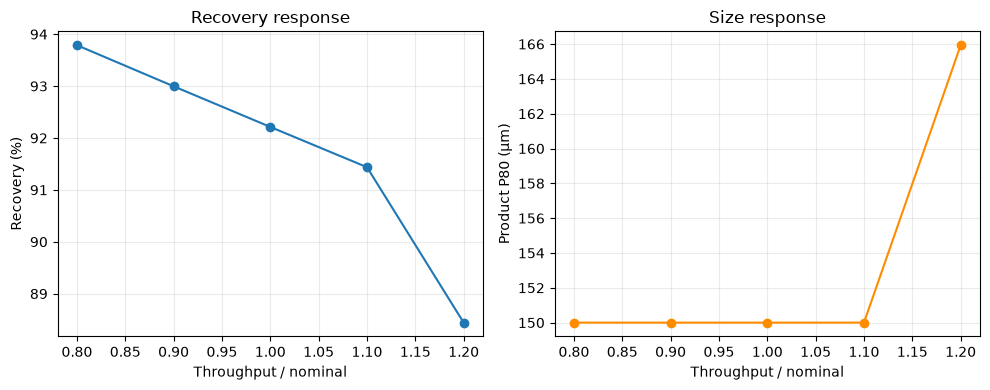

In [11]:
# Plot responses from the independently solved operating points.
import matplotlib.pyplot as plt

factors = [0.8, 0.9, 1.0, 1.1, 1.2]
runs = [response_0_8, response_0_9, response_1_0, response_1_1, response_1_2]
rates = [run.metrics["recovery_pct"] for run in runs]
sizes = [run.metrics["p80_um"] for run in runs]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(factors, rates, marker="o")
axes[0].set(xlabel="Throughput / nominal", ylabel="Recovery (%)", title="Recovery response")
axes[1].plot(factors, sizes, marker="o", color="darkorange")
axes[1].set(xlabel="Throughput / nominal", ylabel="Product P80 (µm)", title="Size response")
for axis in axes:
    axis.grid(True, alpha=0.25)
fig.tight_layout()


La figura 28 de nivel 3 sobre 03 learning informa salidas de puntos operativos resueltos por separado. En la figura 28 de nivel 3 sobre 03 learning, cada marca es una evaluación separada del modelo en el ajuste indicado. En la figura 28 de nivel 3 sobre 03 learning, contrasta recuperación, tamaño y energía con el contrato. La línea de la figura 28 solo guía la comparación.

En el nivel 3 de 03 learning, la interpretación 1 es que todos los objetivos supervisados de este repositorio los genera el motor de proceso OreFlow. En el nivel 3 de 03 learning, la interpretación 2 es que por ello, el aprendiz aproxima un simulador determinista, no una planta instrumentada. En el nivel 3 de 03 learning, la interpretación 3 es que las particiones de interpolación miden desempeño entre estados de casos presentes en entrenamiento. En el nivel 3 de 03 learning, la interpretación 4 es que las particiones que excluyen un caso o un grupo mineral retiran ejemplos cada vez más relacionados y plantean preguntas de transferencia más exigentes. En el nivel 3 de 03 learning, la interpretación 5 es que la unidad de partición debe coincidir con el uso previsto: una partición aleatoria por fila puede filtrar la identidad del caso mediante variables de proceso correlacionadas. En el nivel 3 de 03 learning, la interpretación 6 es que el escalamiento, la selección de variables y el ajuste de hiperparámetros deben ocurrir dentro de cada pliegue. En el nivel 3 de 03 learning, la interpretación 7 es que informa errores por objetivo y grupo reservado, no solo una puntuación agregada, porque un promedio bueno puede ocultar fallas severas para una familia mineral desconocida. En el nivel 3 de 03 learning, la interpretación 8 es que los intervalos predictivos requieren cobertura empírica. En el nivel 3 de 03 learning, la interpretación 9 es que estas evaluaciones no establecen causalidad ni validan una decisión operativa. En el nivel 3 de 03 learning, la interpretación 10 es que para esas preguntas separadas hacen falta observaciones de planta y una función de pérdida específica de la decisión. En el nivel 3 de 03 learning, la interpretación 11 es que el diseño versionado reúne 3.072 estados simulados de doce circuitos de autoría propia. En el nivel 3 de 03 learning, la interpretación 12 es que ese tamaño mejora la repetibilidad del experimento, pero no genera 3.072 escenarios geológicos independientes: las filas comparten definiciones de caso, parámetros minerales y supuestos de circuito. En el nivel 3 de 03 learning, la interpretación 13 es que un modelo entrenado con esas etiquetas puede reproducir muy bien el simulador y aun así equivocarse sobre una planta real. En el nivel 3 de 03 learning, la interpretación 14 es que para evaluar transferencia, inspecciona residuos por caso, escala de los objetivos y grupos minerales ausentes del entrenamiento. En el nivel 3 de 03 learning, la interpretación 15 es que una partición agrupada evita que filas casi duplicadas crucen la separación, pero no prueba una familia mineral que el estudio nunca incluyó. En el nivel 3 de 03 learning, la interpretación 16 es que compara cada predicción aprendida con el resultado exacto de proceso antes de usarla para ordenar decisiones operativas. En el nivel 3 de 03 learning, la extensión 1 muestra que una comparación justa usa los mismos pliegues, objetivos, preprocesamiento y presupuesto de ajuste. En el nivel 3 de 03 learning, la extensión 2 muestra que el estimador seleccionado debe elegirse dentro de los pliegues de entrenamiento porque usar casos reservados para elegirlo convierte la puntuación final en otro resultado de ajuste. En el nivel 3 de 03 learning, la extensión 3 muestra que conserva una referencia simple, como el predictor de media de entrenamiento, y muestra la distribución entre grupos reservados para evaluar si la complejidad adicional ayuda a transferir y no solo a interpolar.

## Resultados

**Respuesta:** En esta lección de nivel 3 sobre 03 learning, el circuito ejecutado informa una recuperación de 93.788 por ciento para «Compara surrogates y transfiere a minerales no vistos» en el primer tratamiento controlado.

Compara el mapa de calor dentro de cada objetivo. La brecha entre R² agrupado y dentro de caso evidencia efectos de medias por caso. Retenciones de casos y grupos son pruebas de transferencia más exigentes, no garantías en plantas futuras. La cobertura GP es empírica en esta partición generada. Todas las etiquetas proceden del motor; para validación en terreno se requieren datos independientes de planta.

## Resumen

El resultado acotado es que los surrogates aproximan el motor OreFlow en doce circuitos de autoría propia. El notebook informa cómo cambian las métricas con retenciones estrictas, sin afirmar capacidad predictiva general en planta ni un algoritmo nuevo.

## Referencias

- https://doi.org/10.1023/A:1010933404324
- https://doi.org/10.1214/aos/1013203451
- https://doi.org/10.48550/arXiv.1412.6980
- https://doi.org/10.1017/CBO9780511790423
- https://doi.org/10.1023/A:1010933404324